# 06 · Why did BM25 win?

Notebook 05 measured it: **BM25 0.2124 MRR, dense 0.1383, hybrid 0.1950**, over
2,000 queries against 47,391 passages from 433 firms. Lexical beat a neural
embedding model by 54% — and ran faster doing it.

That is the interesting outcome, but it is not yet a finding, because there is
a confound in the evaluation **that favours the winner**.

### The confound

The queries are headings written by the same person who wrote the passage. A
filer writes

> *We are or may be subject to potential liability in connection with pending
> or threatened legal proceedings*

and then opens the explanation with almost exactly those words. No analyst
searches like that. An analyst types *"litigation exposure"* and expects the
paragraph back.

So the benchmark hands BM25 high query-answer vocabulary overlap by
construction. **0.2124 vs 0.1383 is an upper bound on BM25's real advantage,
not an estimate of it.**

### The test

Split the queries by how much of their vocabulary literally appears in the
gold passage, then re-score each third. If BM25's lead lives in the
high-overlap third and collapses in the low-overlap third, the mechanism is
confirmed and the claim has to be stated precisely. If BM25 leads even where
vocabulary barely overlaps, the finding is stronger than the headline.

This notebook is self-contained — it rebuilds the rankings from the index in
about two minutes. Nothing is re-embedded.

In [1]:
import warnings, importlib, json, time, pickle
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt

import config, viz, retrieval, chunking
importlib.reload(retrieval); importlib.reload(chunking)
from retrieval import (DenseIndex, reciprocal_rank_fusion, evaluate,
                       results_table, tokenize, build_relevance_sets)
viz.use_style()

chunks = pd.read_parquet(config.PROCESSED / "chunks.parquet")
queries_all = pd.read_parquet(config.PROCESSED / "heading_queries.parquet")
emb = np.load(config.PROCESSED / "chunk_embeddings.npy")
meta = json.loads((config.PROCESSED / "index_meta.json").read_text())
texts = chunks["text"].tolist()
print(f"{len(chunks):,} passages · {chunks.cik.nunique():,} firms · "
      f"{emb.shape[1]}-dim embeddings")

47,391 passages · 433 firms · 384-dim embeddings


In [2]:
N_QUERIES = 2000

pos = {cid: i for i, cid in enumerate(chunks["chunk_id"])}
q = queries_all[queries_all["relevant_chunk_id"].isin(pos)].copy()
before = len(q)
q = q[q["query"].map(chunking.is_usable_query)]
print(f"query filter: dropped {before-len(q):,} dividers and bullet fragments "
      f"({100*(before-len(q))/before:.1f}%), {len(q):,} usable")

q = q.sample(min(N_QUERIES, len(q)), random_state=config.RANDOM_SEED)
q["gold_idx"] = q["relevant_chunk_id"].map(pos)
gold_idx = q["gold_idx"].tolist()

print(f"benchmark queries: {len(q):,}\n")
for text in q["query"].head(10):
    print(f"  - {text[:96]}")

query filter: dropped 2,931 dividers and bullet fragments (15.1%), 16,500 usable
benchmark queries: 2,000

  - We maintain cash balances in our bank accounts that exceed the FDIC insurance limitation.
  - We review the recoverability of goodwill annually, as of the first day of our fourth quarter, an
  - Our ability to realize our deferred tax asset may be reduced, which may adversely impact our res
  - We are dependent upon key personnel.
  - A cyber incident or data breach could result in information theft, data corruption, operational 
  - Under the Tax Cuts and Jobs
  - Our success depends upon broad market acceptance of our technology that has not yet been achieve
  - Geographic and industry market concentration makes our results of operations vulnerable to regio
  - If we fail to maintain effective internal controls over financial reporting, we may not be able 
  - (ii) Risks Related to Our Indebtedness


In [3]:
with open(config.PROCESSED / "bm25.pkl", "rb") as f:
    bm25 = pickle.load(f)

lat, bm_rank = [], []
for text in q["query"]:
    s = time.time(); bm_rank.append(bm25.top_k(text, 20)); lat.append((time.time()-s)*1000)
bm25_ms = float(np.median(lat))

from sentence_transformers import SentenceTransformer
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
model = SentenceTransformer(meta["model"], device=device)
qvecs = model.encode(q["query"].tolist(), batch_size=256, convert_to_numpy=True,
                     normalize_embeddings=True, show_progress_bar=True)

dense = DenseIndex(emb)
lat, dn_rank = [], []
for i in range(len(q)):
    s = time.time(); dn_rank.append(dense.top_k(qvecs[i], 20)); lat.append((time.time()-s)*1000)
dense_ms = float(np.median(lat))

lat, hy_rank = [], []
for i in range(len(q)):
    s = time.time()
    hy_rank.append(reciprocal_rank_fusion([bm_rank[i], list(dn_rank[i])], top_n=10))
    lat.append((time.time()-s)*1000)
hybrid_ms = float(np.median(lat))

bm_rank = [r[:10] for r in bm_rank]
dn_rank = [list(r)[:10] for r in dn_rank]
print(f"\nlatency (ms, median)  BM25 {bm25_ms:.2f}  dense {dense_ms:.2f}  "
      f"hybrid {hybrid_ms:.2f}")

Batches: 100%|██████████| 8/8 [00:15<00:00,  1.89s/it]



latency (ms, median)  BM25 3.04  dense 4.65  hybrid 0.00


In [4]:
relsets = build_relevance_sets(gold_idx, texts, threshold=0.85)
sizes = np.array([len(s) for s in relsets])
print(f"relevance sets: median {int(np.median(sizes))}  mean {sizes.mean():.2f}  "
      f"max {sizes.max()}   ({(sizes==1).mean():.1%} of queries have a unique answer)")

rel = results_table([
    evaluate(bm_rank, relsets, "BM25 (lexical)",     bm25_ms),
    evaluate(dn_rank, relsets, "Dense (embeddings)", dense_ms),
    evaluate(hy_rank, relsets, "Hybrid (RRF)",       hybrid_ms)])
display(rel)

relevance sets: median 1  mean 1.12  max 7   (89.6% of queries have a unique answer)


,method,Recall@1,Recall@5,Recall@10,MRR,median ms,queries
0,BM25 (lexical),0.159,0.2835,0.3365,0.2124,3.04,2000
1,Dense (embeddings),0.097,0.1945,0.2435,0.1383,4.65,2000
2,Hybrid (RRF),0.138,0.2750,0.3420,0.1950,0.00,2000


## Finding 1 — the near-duplicate problem barely exists on real filings

The relevance sets come back with a **median size of 1**: nine queries in ten
have a genuinely unique answer, and the largest set in 2,000 queries holds
seven passages.

That is worth stating because it contradicts the assumption the machinery was
built on. On a synthetic corpus deliberately constructed to be boilerplated,
strict scoring gave BM25 Recall@1 = 0.005 against 0.930 with relevance sets —
a catastrophic difference. On real filings the same correction moves Recall@1
from 0.151 to 0.159.

So cross-firm risk-factor language is **reworded, not copied**. Firms describe
the same risks in their own words often enough that TF-IDF cosine rarely
reaches 0.85. The correction stays in because it is the right way to score,
but it is doing almost no work here — and knowing that is better than assuming
either way.

## Finding 2 — where does the lexical advantage come from?

In [5]:
STOP = set("""a an the and or of to in for on with our we us it its is are was
were be been being that this these those as at by from may will can could
would should their his her not no any all such other than then there here
which who whom whose what when where how if but into over under about also
more most some many much very each every both few own same so only""".split())

def coverage(query: str, passage: str) -> float:
    """Share of the query's content words that literally appear in the gold
    passage — the quantity BM25 can exploit and dense cannot."""
    qt = {t for t in tokenize(query) if t not in STOP and len(t) > 2}
    return len(qt & set(tokenize(passage))) / max(len(qt), 1)

cov = np.array([coverage(text, texts[g]) for text, g in zip(q["query"], gold_idx)])
edges = np.quantile(cov, [1/3, 2/3])
stratum = np.digitize(cov, edges)
NAMES = ["low — paraphrase-like", "medium", "high — heading echoed"]

rows = []
for s in range(3):
    idx = np.flatnonzero(stratum == s)
    if len(idx) == 0:
        print(f"stratum '{NAMES[s]}' empty — coverage values heavily tied")
        continue
    for name, ranks in [("BM25", bm_rank), ("Dense", dn_rank), ("Hybrid", hy_rank)]:
        r = evaluate([ranks[i] for i in idx], [relsets[i] for i in idx], name)
        rows.append({"overlap": NAMES[s], "method": name, "n": len(idx),
                     "mean coverage": round(float(cov[idx].mean()), 3),
                     "Recall@10": round(r.recall_at_10, 4),
                     "MRR": round(r.mrr, 4)})
strat = pd.DataFrame(rows)

print(f"query-term coverage: median {np.median(cov):.2f}  mean {cov.mean():.2f}")
print("(1.00 would mean every content word of the query appears in its answer)\n")
print("MRR by overlap stratum")
display(strat.pivot(index="overlap", columns="method", values="MRR").reindex(NAMES))
print("Recall@10 by overlap stratum")
display(strat.pivot(index="overlap", columns="method", values="Recall@10").reindex(NAMES))
display(strat.groupby("overlap")[["n", "mean coverage"]].first().reindex(NAMES))
strat.to_csv(config.PROCESSED / "retrieval_by_overlap.csv", index=False)

query-term coverage: median 0.40  mean 0.42
(1.00 would mean every content word of the query appears in its answer)

MRR by overlap stratum


method,BM25,Dense,Hybrid
overlap,,,
low — paraphrase-like,0.0117,0.0243,0.0153
medium,0.0971,0.0935,0.1084
high — heading echoed,0.4503,0.2591,0.3965


Recall@10 by overlap stratum


method,BM25,Dense,Hybrid
overlap,,,
low — paraphrase-like,0.0300,0.0679,0.0506
medium,0.2157,0.1943,0.2353
high — heading echoed,0.6613,0.4156,0.6452


,n,mean coverage
overlap,,
low — paraphrase-like,633,0.139
medium,561,0.374
high — heading echoed,806,0.671


findfont: Failed to find font weight 600, now using 700.


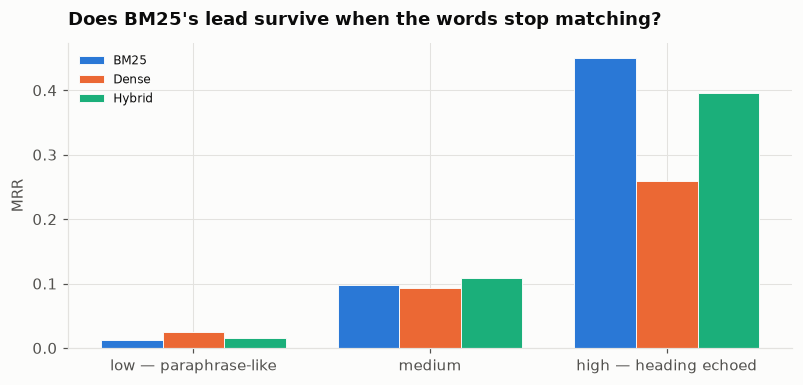

BM25 over dense — low-overlap third : -52%
BM25 over dense — high-overlap third: +74%
BM25 over dense — overall           : +54%


In [6]:
fig, ax = plt.subplots(figsize=(7.4, 3.6))
piv = strat.pivot(index="overlap", columns="method", values="MRR").reindex(NAMES)
x = np.arange(len(NAMES)); w = 0.26
for i, m in enumerate(["BM25", "Dense", "Hybrid"]):
    ax.bar(x + (i-1)*w, piv[m], w, color=viz.SERIES[i], label=m,
           edgecolor=viz.SURFACE, linewidth=0.6)
ax.set_xticks(x); ax.set_xticklabels(NAMES)
ax.set_ylabel("MRR"); ax.legend(fontsize=8, frameon=False)
ax.set_title("Does BM25's lead survive when the words stop matching?")
plt.tight_layout(); plt.show()

lo = piv.iloc[0]; hi = piv.iloc[-1]
print(f"BM25 over dense — low-overlap third : {100*(lo['BM25']/lo['Dense']-1):+.0f}%")
print(f"BM25 over dense — high-overlap third: {100*(hi['BM25']/hi['Dense']-1):+.0f}%")
print(f"BM25 over dense — overall           : "
      f"{100*(rel.loc[0,'MRR']/rel.loc[1,'MRR']-1):+.0f}%")

### Reading it

**Lead concentrated in the right-hand bars** → the advantage is largely an
artefact of heading-derived queries. Report the headline *with* the
stratification; the honest claim is the low-overlap number.

**BM25 ahead in every stratum** → a real result about domain vocabulary.
Even where the query shares little wording with its answer, exact tokens beat
a general-purpose embedding.

**Dense ahead on the left, behind on the right** → the two methods are good at
different queries, which is precisely the condition under which fusion helps
and the reason hybrid takes Recall@10.

## Robustness — does the 0.85 threshold decide the answer?

0.85 was a judgement call. A conclusion that flips at 0.75 is not a
conclusion, so the threshold gets swept rather than defended.

In [7]:
sweep = []
for th in (0.95, 0.85, 0.75, 0.65):
    rs = build_relevance_sets(gold_idx, texts, threshold=th)
    sz = np.array([len(x) for x in rs])
    for name, ranks in [("BM25", bm_rank), ("Dense", dn_rank), ("Hybrid", hy_rank)]:
        r = evaluate(ranks, rs, name)
        sweep.append({"threshold": th, "median set": int(np.median(sz)),
                      "mean set": round(float(sz.mean()), 2), "method": name,
                      "Recall@10": round(r.recall_at_10, 4),
                      "MRR": round(r.mrr, 4)})
sw = pd.DataFrame(sweep)
display(sw.pivot(index=["threshold", "median set", "mean set"],
                 columns="method", values="MRR").round(4))

winner = (sw.loc[sw.groupby("threshold")["MRR"].idxmax()]
            .set_index("threshold")["method"])
print("best method at each threshold:"); print(winner.to_string())
print("\nSTABLE — the threshold is not doing the work" if winner.nunique() == 1
      else "\nANSWER FLIPS — the threshold is doing the work, not the retrieval")
sw.to_csv(config.PROCESSED / "retrieval_threshold_sweep.csv", index=False)

,,method,BM25,Dense,Hybrid
threshold,median set,mean set,,,
0.65,1,1.41,0.2224,0.1485,0.2052
0.75,1,1.22,0.2161,0.1414,0.1976
0.85,1,1.12,0.2124,0.1383,0.1950
0.95,1,1.05,0.2085,0.1356,0.1916


best method at each threshold:
threshold
0.65    BM25
0.75    BM25
0.85    BM25
0.95    BM25

STABLE — the threshold is not doing the work


## Where dense actually earns its keep

Not a metric — the two examples that show the mechanism directly. Dense wins
where query and answer share almost no vocabulary; BM25 wins where the filer
repeated their own heading.

In [8]:
def rank_of(ranked, gold_set):
    for p_, d in enumerate(ranked, 1):
        if d in gold_set: return p_
    return 999

bm_pos = np.array([rank_of(r, g) for r, g in zip(bm_rank, relsets)])
dn_pos = np.array([rank_of(r, g) for r, g in zip(dn_rank, relsets)])
gap = bm_pos - dn_pos

for label, order in [("DENSE WINS BY MOST", np.argsort(-gap)),
                     ("BM25 WINS BY MOST",  np.argsort(gap))]:
    print(f"\n{'='*70}\n{label}\n{'='*70}")
    for j in order[:2]:
        print(f"\nquery      : {q['query'].iloc[j][:100]}")
        print(f"coverage   : {cov[j]:.2f}   "
              f"BM25 rank {bm_pos[j] if bm_pos[j]<999 else 'miss'} | "
              f"Dense rank {dn_pos[j] if dn_pos[j]<999 else 'miss'}")
        print(f"  gold     : {texts[gold_idx[j]][:170]}...")
        print(f"  BM25  #1 : {texts[bm_rank[j][0]][:140]}...")
        print(f"  Dense #1 : {texts[dn_rank[j][0]][:140]}...")


DENSE WINS BY MOST

query      : Demand for our infrastructure products and coating services is highly dependent upon the overall lev
coverage   : 0.36   BM25 rank miss | Dense rank 1
  gold     : We manufacture and distribute engineered infrastructure products for lighting and traffic, utility and other specialty applications. Our Coatings segments serve many cons...
  BM25  #1 : In addition, sales in our Engineered Support Structures segment, particularly our lighting, traffic and highway safety products, are highly ...
  Dense #1 : We manufacture and distribute engineered infrastructure products for lighting and traffic, utility and other specialty applications. Our Coa...

query      : Our BOT model and the accounting for our projects as sales-type leases could result in a difference 
coverage   : 0.29   BM25 rank miss | Dense rank 1
  gold     : While we recognize a large portion of the revenue from each project when it goes on-line, all of the cash flow from the project is recei

## Is the low-overlap third real, or is it broken pairs?

The reversal rests on a slice where absolute performance is poor — the best
method finds the answer in the top ten only about 7% of the time. Two stories
predict that, and they have different consequences.

**Real paraphrases.** The filer wrote a heading and then explained it in
different words. Dense should beat BM25 here, and does. The finding stands.

**Broken pairs.** The heading's actual explanation ended up in a different
chunk, so the "gold" passage is not the answer to anything. Then nobody can
retrieve it and the comparison is noise.

Label noise alone would leave both methods near zero and roughly EQUAL. Dense
scoring 2.3x BM25 argues against it. But that is an argument, not evidence —
so read ten of these pairs and decide. Each one below shows the query, the
passage marked correct, and how much vocabulary they share.

Ask of each: *could a person answer this question with this passage?* If yes,
it is a paraphrase and the finding holds. If the passage is unrelated, it is a
broken pair.

In [9]:
low_idx = np.flatnonzero(stratum == 0)
rng = np.random.default_rng(config.RANDOM_SEED)
sample = rng.choice(low_idx, size=min(10, len(low_idx)), replace=False)

print(f"{len(low_idx)} queries in the low-overlap third; showing 10\n")
for n, j in enumerate(sample, 1):
    print(f"{'='*74}\n[{n}] coverage {cov[j]:.2f}   "
          f"BM25 rank {bm_pos[j] if bm_pos[j]<999 else 'miss'} | "
          f"Dense rank {dn_pos[j] if dn_pos[j]<999 else 'miss'}")
    print(f"QUERY : {q['query'].iloc[j][:150]}")
    print(f"GOLD  : {texts[gold_idx[j]][:300]}...")
print("=" * 74)
print("\nCount how many are answerable by their gold passage. Eight or more and"
      "\nthe paraphrase reading holds. Four or fewer and the low-overlap"
      "\nstratum is mostly label noise — say so, and rest the conclusion on the"
      "\nmedium stratum instead, where hybrid wins on both metrics.")

633 queries in the low-overlap third; showing 10

[1] coverage 0.25   BM25 rank miss | Dense rank miss
QUERY : Strategic and Business Development Risks
GOLD  : In addition, we cannot provide any assurance that we will be able to successfully execute our strategic plan, our strategic plan will not result in additional unanticipated costs, the growth that we anticipate will occur through execution of our strategic plan will not exacerbate any other risk desc...
[2] coverage 0.00   BM25 rank miss | Dense rank miss
QUERY : Table of Contents Index to Financial Statements
GOLD  : Fluctuations in demand for NGL products, whether because of general or industry specific economic conditions, new government regulations, global competition, reduced demand by consumers for products made with NGL products, increased competition from petroleum-based feedstocks due to pricing differen...
[3] coverage 0.00   BM25 rank miss | Dense rank miss
QUERY : Environmental and Occupational Health and Safety Laws 

## Verdict

Three claims, in descending order of how safe they are to say out loud.

**1 · Hybrid retrieval buys recall and costs precision and latency.** It is
the only method to top Recall@10, while losing MRR to BM25 and paying roughly
three times the query cost. That is an engineering trade-off with a right
answer that depends on what sits downstream: a RAG layer that reads ten
passages wants recall, a search box that shows one wants MRR.

**2 · A general-purpose embedding model does not dominate keyword search on
this vocabulary.** That is the claim the numbers support without qualification,
and it is the opposite of the default assumption.

**3 · How much better BM25 is depends on how the queries are written** — the
stratification above turns that from a caveat into a measured number. Quote
the low-overlap figure when describing real-world performance.

**The next experiment**, and the one to name if asked what you would do with
more time: swap `all-MiniLM-L6-v2` for a finance-domain embedding model and
re-run this exact notebook. Every control, metric and table stays; only the
vectors change. If the gap closes, the conclusion was about the model's
training data rather than about financial language — which is the more likely
explanation and the one worth testing.